In [1]:
import papermill as pm
import scrapbook as sb
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import statistics

In [2]:
n_runs = 13

RES_pf  = []
RES_B   = []
RES_sr  = []
RES_rew = []

for i in range(n_runs):
    output_file = f'pm_velocity{i}.ipynb'
    nb = sb.read_notebook(output_file)
    RES_pf.append(nb.scraps['res_pf'].data)
    RES_B.append(nb.scraps['res_B'].data)
    RES_sr.append(nb.scraps['res_sr'].data)
    RES_rew.append(nb.scraps['res_rew'].data)

In [3]:
mean_sr = statistics.mean([d['mean'] for d in RES_sr])
mean_sr

0.9753828758196296

In [4]:
stdev_sr = statistics.mean([d['std'] for d in RES_sr])
stdev_sr

0.029121581821639497

(0.9, 1.1)

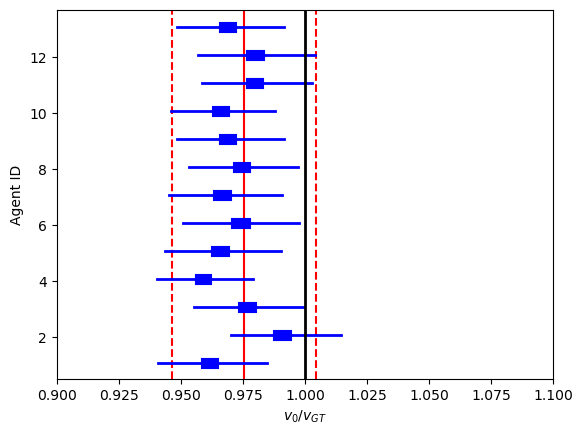

In [5]:
plt.axvline(mean_sr, c='r')
plt.axvline(RES_sr[0]['mean'] - stdev_sr, c='r', ls='--')
plt.axvline(RES_sr[0]['mean'] + stdev_sr, c='r', ls='--')

#for i, r in enumerate(RES_pf):
#    mean = r['mean']
#    ci_mean = r['ci_mean']
#    stdev = r['std']
#    pos = i - 0.1 + 1
#    plt.plot([mean - stdev, mean + stdev], [pos, pos], '-', lw=2, c='orange')  # Whiskers
#    plt.plot(ci_mean, [pos, pos], '-', lw=8, c='orange')  # Mean point

for i, r in enumerate(RES_B):
    mean = r['mean']
    ci_mean = r['ci_mean']
    stdev = r['std']
    pos = i + 0.1 + 1
    plt.plot([mean - stdev, mean + stdev], [pos, pos], 'b-', lw=2)  # Whiskers
    plt.plot(ci_mean, [pos, pos], '-b', lw=8)  # Mean point


plt.axvline(1.0, ls='-', c='k', lw=2)
plt.xlabel(r"$v_0/v_{GT}$")
plt.ylabel("Agent ID")

plt.xlim([0.9, 1.1])
    

Text(0, 0.5, 'Count')

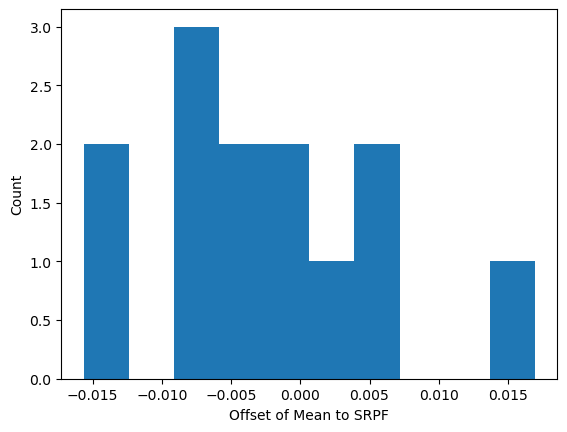

In [6]:
plt.hist([d['mean'] - mean_sr for d in RES_B])
plt.xlabel("Offset of Mean to SRPF")
plt.ylabel("Count")

Text(0, 0.5, 'Count')

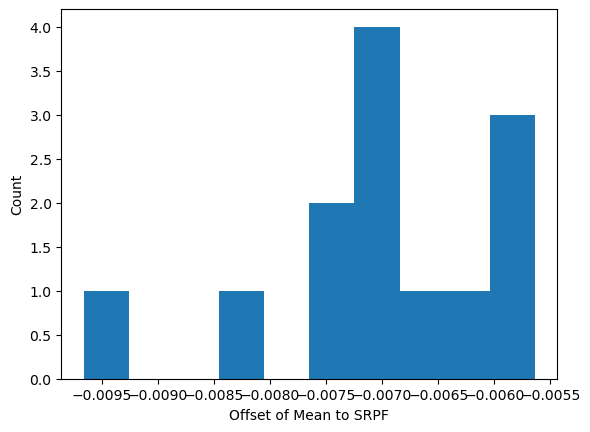

In [7]:
plt.hist([d['std'] - stdev_sr for d in RES_B])
plt.xlabel("Offset of Mean to SRPF")
plt.ylabel("Count")